### Problema de Mezclas con Ecuaciones Diferenciales 0724

<center><img src=tanque.png width="200" class='center'></center>

El volumen de un tanque con una entrada $V_{1}$, una salida $V_{2}$ con un volumen inicial $V_{0}$ en un instante $t$ de tiempo $V(t)$  está descrito por la ecuación

$$V(t) = V_{0} + (V_{1}-V_{2})t$$

Mientras que, la cantidad de sal en el momento $t$ $(y(t))$ esta descrita por el producto del volumen por la concentración, con la siguiente ec. diferencial

$$\frac{dy}{dt} = V_{1}c_{1} - V_{2}c_{2}$$

$$c_{2} = \frac{y(t)}{V(t)}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

Condiciones iniciales

In [8]:
v1 = 2 #L/s
v2 = 3 #L/s
vo = 40 #L
c1 = 5 #g/L

Ecuación diferencial

In [9]:
def dydt(t, y):
    v = vo + (v1 - v2) * t
    if v <= 0:
        return 0
    c2 = y / v
    return v1 * c1 - v2 * c2

#Evento
def event(t, y):
    return vo + (v1 - v2) * t

event.terminal = True
event.direction = -1

#Intervalo de resolución y condisiones iniciales
tspan = np.array([0, 1000])
y0 = np.array([10]) #Cantidad inicial de sal en el tanque

sol = solve_ivp(dydt, tspan, y0, events=event)

En solve_ivp exite un parametro llamado evento (event) que sucede en los ceros de una cierta función $f(t)$, en este caso es cuando $V(t) = 0$, este tiene dos subparámetros
- terminal : booleano, si es True activará la condición, si es False no hará nada.
- direction : -1, 0, 1, si es positivo, el evento se activará de negativo a positivo al cruzar el cero de la función, negativo viceversa y 0 lo activará en cualquier dirección.

Se presentan los datos de forma gráfica

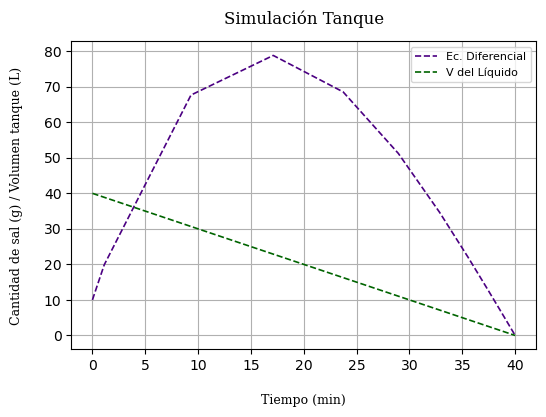

In [10]:
plt.figure(figsize=(6, 4))

plt.plot(sol.t, sol.y[0], '--', color='indigo', label='Ec. Diferencial',lw=1.2)
plt.plot(sol.t, vo + (v1 - v2) * sol.t, '--',color='darkgreen', label='V del Líquido',lw=1.2)

plt.title('Simulación Tanque', fontsize=12, fontfamily='serif', pad=13)
plt.xlabel('Tiempo (min)',fontsize=9, fontfamily='serif',labelpad=15)
plt.ylabel('Cantidad de sal (g) / Volumen tanque (L)',fontsize=9, fontfamily='serif',labelpad=15)

plt.grid(True)
plt.legend(fontsize=8)
plt.show()